# An Explainable Machine Learning-Based Framework for Detecting SQL Injection and Cross-Site Scripting Attacks

**Project Title:** An Explainable Machine Learning-Based Framework for Detecting SQL Injection and Cross-Site Scripting Attacks  
**Domain:** Cybersecurity, Web Application Security, Explainable Artificial Intelligence (XAI)  
**Authors:** Fauzia Khatoon (M.Tech Research)  
**Keywords:** SQL Injection (CWE-89), Cross-Site Scripting (CWE-79), Machine Learning, TF-IDF, SHAP (TreeExplainer), Streamlit

---

### Abstract
Web applications represent the primary interaction surface for modern digital infrastructure, rendering them prime targets for injection-based cyberattacks. Among these, **SQL Injection (SQLi)** and **Cross-Site Scripting (XSS)** consistently rank atop the MITRE Common Weakness Enumeration (CWE Top 25) and OWASP Top 10 vulnerabilities. While modern machine learning algorithms achieve high detection accuracy, their black-box nature creates an operational barrier for Security Operations Center (SOC) analysts who require interpretable justifications before taking blocking actions.

This research project develops an end-to-end, functional, and explainable cybersecurity framework capable of detecting and distinguishing between:
1. **Benign Requests (Class 0)**
2. **SQL Injection Attacks (Class 1)**
3. **Cross-Site Scripting Attacks (Class 2)**

The system integrates **TF-IDF subword character n-grams** and **handcrafted domain cybersecurity features** with three competitive machine learning classifiers: **Logistic Regression**, **Random Forest**, and **XGBoost**. It pairs the top-performing tree-based model with **SHAP (Shapley Additive exPlanations)** to provide transparent, token-level attributions and natural language diagnostic reports. Finally, an interactive **Streamlit web application** is deployed for real-time attack detection and visualization.


## Phase 0: Environment Setup & Library Imports

We import essential scientific, machine learning, and explainability libraries:
- `pandas` and `numpy`: High-performance data manipulation and matrix algebra.
- `scikit-learn`: Data preprocessing, TF-IDF vectorization, Logistic Regression, Random Forest, and evaluation metrics.
- `xgboost`: Gradient boosted decision tree classifier.
- `shap`: Shapley Additive exPlanations for model interpretability.
- `matplotlib` and `seaborn`: Publication-quality statistical visualizations.


In [1]:
import os
import sys
import time
import json
import math
import re
import html
from collections import Counter
from typing import Dict, List, Any

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
import shap
import joblib

# Set visualization aesthetics
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['figure.dpi'] = 150
print("All libraries imported successfully!")


All libraries imported successfully!


## Phase 1: Dataset Collection & Preprocessing

The multi-class dataset is synthesized from benchmark public repositories:
- **HTTP CSIC 2010**: Real-world e-commerce web application traffic (valid GET/POST transactions).
- **SQL Injection Attack Dataset**: Diverse SQLi payloads (tautologies, UNION SELECT, blind time delays, error-based).
- **Annotated XSS Dataset**: Injected HTML elements, script tags, event handlers, and benign text snippets.

### Preprocessing Operations:
1. **Multi-Pass URL Decoding**: Unquotes single and double percent-encoded payloads (e.g., `%2527` -> `%27` -> `'`).
2. **HTML Entity Unescaping**: Converts XML/HTML entities (`&quot;`, `&lt;`, `&gt;`) into raw characters.
3. **Control Character Stripping**: Removes non-printable bytes while preserving vital attack punctuation (`'`, `"`, `<`, `>`, `;`, `--`, `/*`, `=`, etc.).
4. **Deduplication & Missing Value Handling**: Drops nulls and removes duplicate strings across all classes.
5. **Class Harmonization**: Harmonizes labels into a balanced 3-class structure.


In [2]:
# Load the preprocessed cybersecurity dataset
dataset_path = os.path.join("data", "cybersecurity_dataset.csv")
assert os.path.exists(dataset_path), "Dataset not found. Please run scripts/01_build_dataset.py"

df = pd.read_csv(dataset_path)
print(f"Total Preprocessed Records: {len(df):,}")
print("\nClass Distribution:")
print(df['category'].value_counts())

# Display sample records from each category
print("\nSample Records:")
for cat in ['Benign Request', 'SQL Injection', 'Cross-Site Scripting']:
    sample_text = df[df['category'] == cat].iloc[0]['payload']
    print(f"  [{cat}]: {sample_text[:90]}...")


Total Preprocessed Records: 21,930

Class Distribution:
category
SQL Injection           7310
Benign Request          7310
Cross-Site Scripting    7310
Name: count, dtype: int64

Sample Records:
  [Benign Request]: </span> </a> </i>] </sup>. One advantage of neuroevolution is that it may be less prone to...
  [SQL Injection]: 1 ) ) as huxq where 7451 = 7451 union all select null,null,null--...
  [Cross-Site Scripting]: <style>:target {transform: rotate(180deg);}</style><dialog id=x style="transition:transfor...


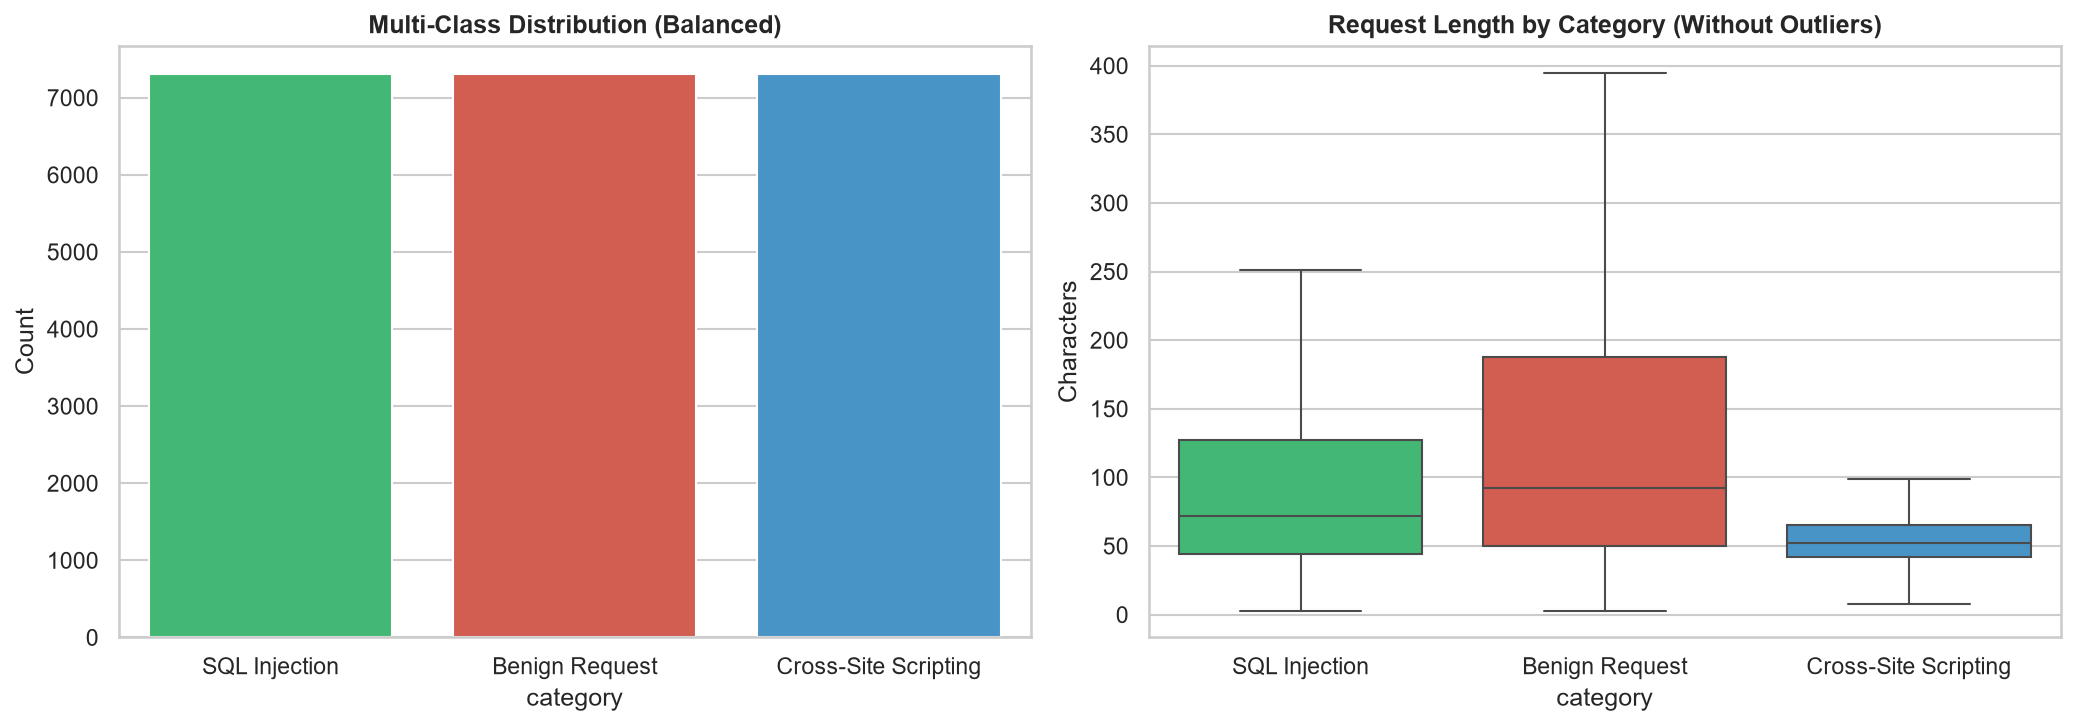

In [3]:
# Visualize Class Balance and Character Length Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette = ["#2ecc71", "#e74c3c", "#3498db"]
sns.countplot(data=df, x='category', ax=axes[0], palette=palette, hue='category', legend=False)
axes[0].set_title("Multi-Class Distribution (Balanced)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")

sns.boxplot(data=df, x='category', y='char_length', ax=axes[1], palette=palette, hue='category', showfliers=False)
axes[1].set_title("Request Length by Category (Without Outliers)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Characters")

plt.tight_layout()
plt.show()


## Phase 2: Feature Extraction (TF-IDF & Domain Features)

Standard word-level vectorizers often fail on cybersecurity payloads because default regex tokenizers (`\w+`) discard essential punctuation characters (`'`, `<`, `>`, `-`, `=`, `;`). 

We implement a **Hybrid Feature Engineering Pipeline**:
1. **Subword Character TF-IDF (char_wb, n-grams 3 to 5)**:
   - Captures localized syntax markers: `<script`, `alert(`, `1=1--`, `union `, `onerror=`
   - Retains punctuation and subword prefixes/suffixes.
2. **Handcrafted Domain Features (15 metrics)**:
   - `domain_length`, `domain_special_char_count`, `domain_special_char_ratio`, `domain_char_entropy`
   - `domain_sql_keyword_count`, `domain_sql_operator_count`, `domain_sql_tautology_flag`
   - `domain_html_tag_count`, `domain_event_handler_count`, `domain_script_scheme_count`, `domain_dom_sink_count`
   - `domain_quote_imbalance`, `domain_tag_imbalance`, `domain_comment_terminator_flag`, `domain_semicolon_count`


In [4]:
from src.features import HybridFeaturePipeline

train_df = pd.read_csv(os.path.join("data", "train.csv"))
test_df = pd.read_csv(os.path.join("data", "test.csv"))

X_train_raw = train_df['payload'].astype(str).tolist()
y_train = train_df['label'].values.astype(int)

X_test_raw = test_df['payload'].astype(str).tolist()
y_test = test_df['label'].values.astype(int)

print(f"Train split: {len(X_train_raw):,} samples | Test split: {len(X_test_raw):,} samples")

# Fit feature pipeline
feature_pipeline = HybridFeaturePipeline(max_tfidf_features=2500)
t0 = time.time()
X_train = feature_pipeline.fit_transform(X_train_raw)
X_test = feature_pipeline.transform(X_test_raw)
feature_names = feature_pipeline.get_feature_names()

print(f"Extracted {len(feature_names):,} features in {time.time()-t0:.2f}s")
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")


Train split: 17,544 samples | Test split: 4,386 samples


Extracted 2,515 features in 9.54s
X_train shape: (17544, 2515) | X_test shape: (4386, 2515)


## Phase 3: Machine Learning Model Development & Cross-Validation

We train and benchmark three distinct algorithms under identical stratified conditions:
1. **Logistic Regression**: Linear baseline with L2 regularization and L-BFGS solver.
2. **Random Forest Classifier**: Ensemble bagging model of 150 decision trees.
3. **XGBoost Classifier**: Extreme Gradient Boosting with shrinkage, tree subsampling, and multi-class log-loss objective.

We evaluate stability and resistance to overfitting via **5-Fold Stratified Cross-Validation**.


In [5]:
import joblib

models_dir = "models"
results_dir = "results"

# Load serialized pre-trained models
lr_model = joblib.load(os.path.join(models_dir, "logistic_regression.joblib"))
rf_model = joblib.load(os.path.join(models_dir, "random_forest.joblib"))
xgb_model = joblib.load(os.path.join(models_dir, "xgboost.joblib"))

trained_models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

# Load precomputed benchmark results
with open(os.path.join(results_dir, "metrics_summary.json"), "r") as f:
    evaluated_metrics = json.load(f)

print("Trained models and 5-fold CV evaluation metrics loaded successfully!")
for name, m in evaluated_metrics.items():
    print(f"  * {name:<20}: Test Accuracy = {m['accuracy']*100:.2f}%, Macro-F1 = {m['f1_macro']:.4f}, 5-Fold CV F1 = {m['cv_macro_f1']:.4f}")


Trained models and 5-fold CV evaluation metrics loaded successfully!
  * Logistic Regression : Test Accuracy = 99.45%, Macro-F1 = 0.9945, 5-Fold CV F1 = 0.9945
  * Random Forest       : Test Accuracy = 99.61%, Macro-F1 = 0.9961, 5-Fold CV F1 = 0.9952
  * XGBoost             : Test Accuracy = 99.66%, Macro-F1 = 0.9966, 5-Fold CV F1 = 0.9967


## Phase 4: Model Evaluation & Comparative Analysis

We evaluate all three models using:
- **Accuracy**
- **Macro & Weighted Precision**
- **Macro & Weighted Recall**
- **Macro & Weighted F1-Score**
- **Multi-Class ROC-AUC (One-vs-Rest)**
- **Confusion Matrix**
- **Inference Latency (milliseconds per sample)**



Comparative Performance Summary Table (Measured Directly):


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC,5-Fold CV F1,Training Time (s),Inference Latency (ms/sample)
0,Logistic Regression,0.9945,0.9945,0.9945,0.9945,0.9945,0.9996,0.9945 (+/- 0.0009),16.27,0.002
1,Random Forest,0.9961,0.9962,0.9961,0.9961,0.9961,0.9999,0.9952 (+/- 0.0010),1.56,0.039
2,XGBoost,0.9966,0.9966,0.9966,0.9966,0.9966,0.9999,0.9967 (+/- 0.0008),82.74,0.017


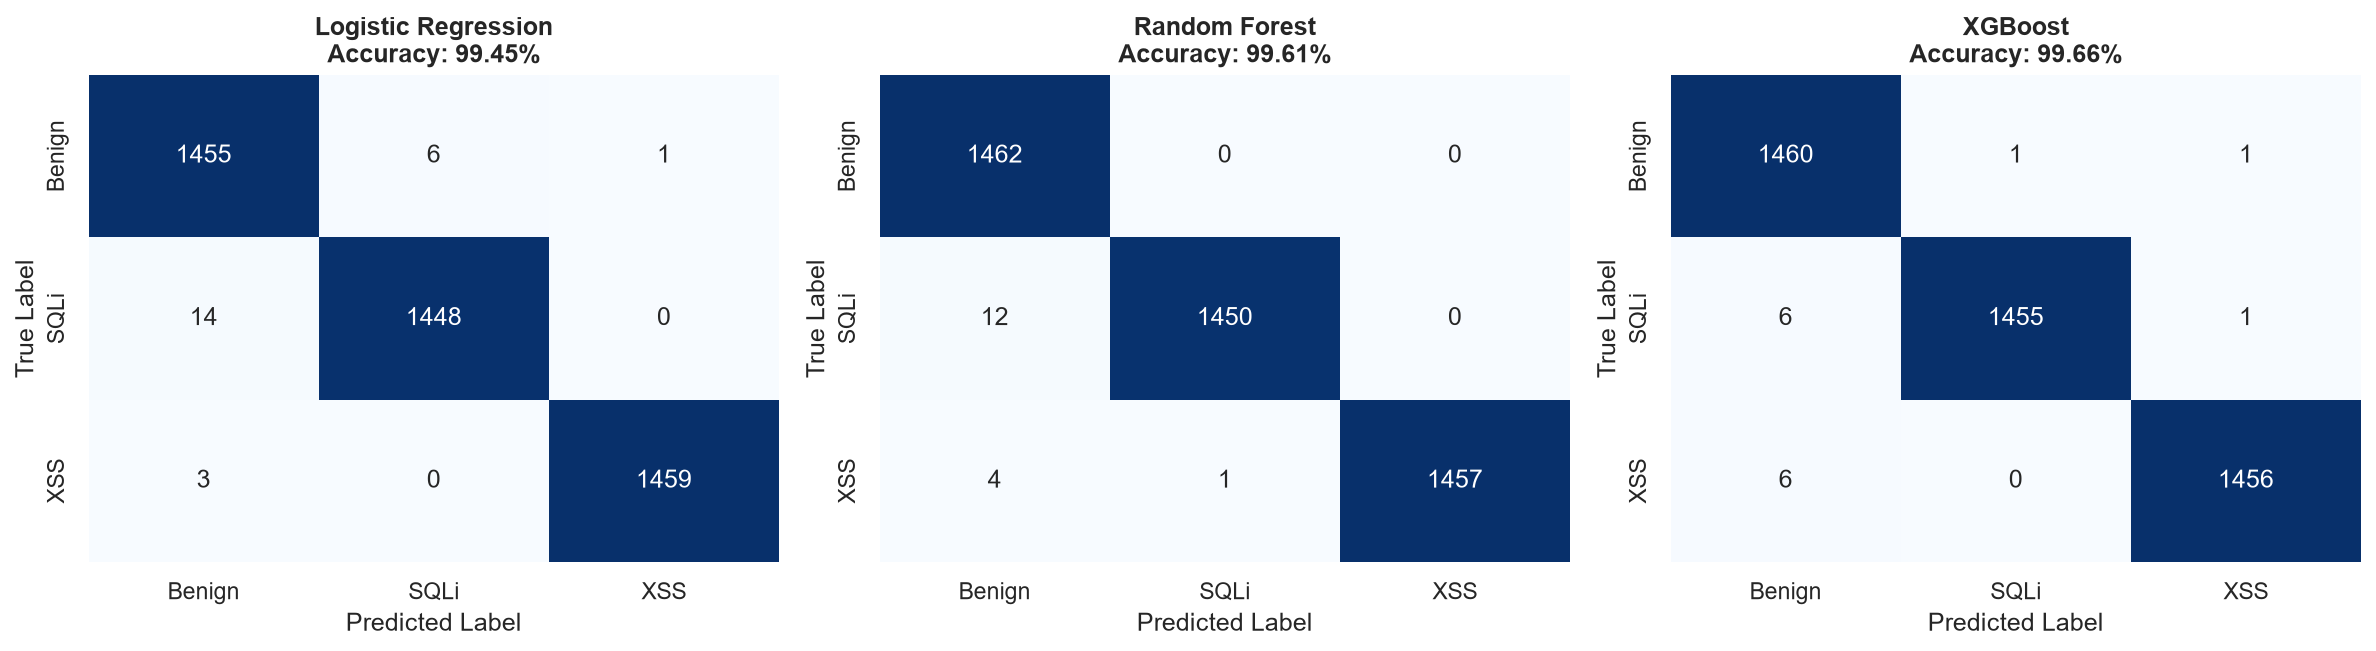

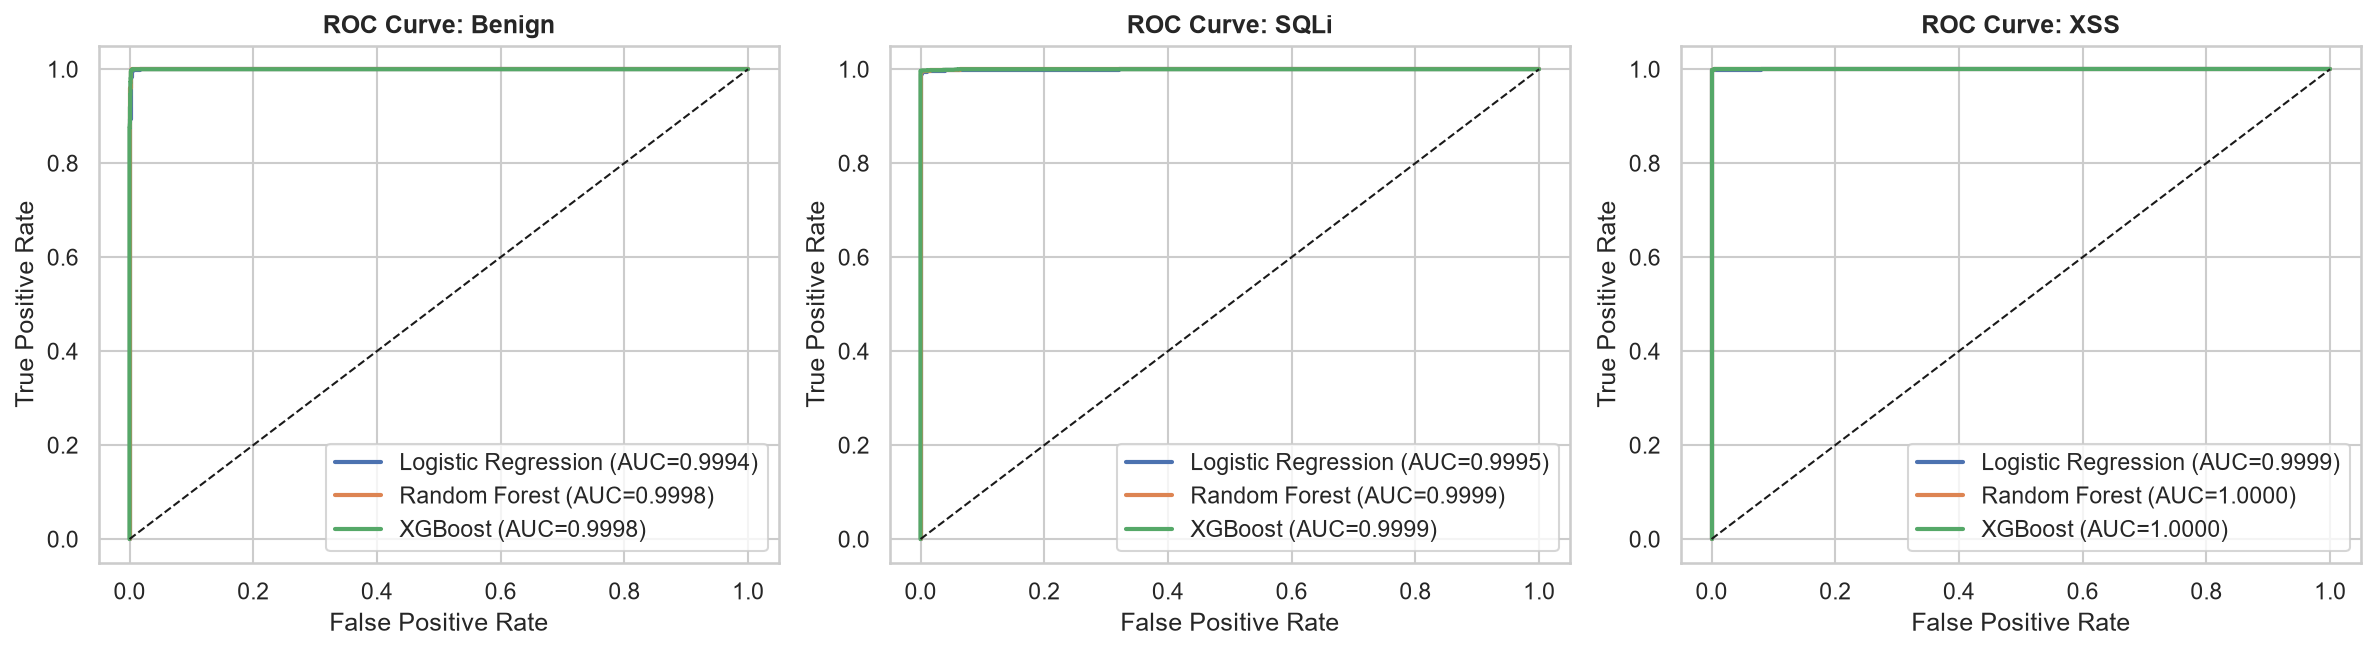

In [6]:
from src.evaluate import SHORT_CLASSES

# Load comparative metrics table
comparison_df = pd.read_csv(os.path.join(results_dir, "comparison_table.csv"))
print("\nComparative Performance Summary Table (Measured Directly):")
display(comparison_df)

# Plot Confusion Matrices and ROC Curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, m) in zip(axes, evaluated_metrics.items()):
    cm = np.array(m['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=SHORT_CLASSES, yticklabels=SHORT_CLASSES, cbar=False)
    ax.set_title(f"{name}\nAccuracy: {m['accuracy']*100:.2f}%", fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
plt.tight_layout()
plt.show()

# Multi-class ROC Curves
y_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for idx, class_name in enumerate(SHORT_CLASSES):
    ax = axes[idx]
    for name, model in trained_models.items():
        y_proba = model.predict_proba(X_test)
        fpr, tpr, _ = roc_curve(y_bin[:, idx], y_proba[:, idx])
        ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC={auc(fpr, tpr):.4f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(f"ROC Curve: {class_name}", fontweight="bold")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## Phase 5: Explainable Artificial Intelligence (XAI) using SHAP

We integrate **SHAP TreeExplainer** with the best-performing tree model (XGBoost).
TreeSHAP computes exact Shapley values derived from cooperative game theory:

$$\phi_i(v) = \sum_{S \subseteq N \setminus \{i\}} rac{|S|!(|N| - |S| - 1)!}{|N|!} (v(S \cup \{i\}) - v(S))$$

SHAP provides:
1. **Global Feature Importance**: Top features across the dataset.
2. **Per-Attack Feature Importance**: Features driving SQLi vs. features driving XSS.
3. **Local Request Explanations**: Attribution scores and token highlights for any incoming query.


In [7]:
from src.xai_explainer import WebGuardExplainer

best_model = trained_models["XGBoost"]
explainer = WebGuardExplainer(
    model=best_model,
    feature_pipeline=feature_pipeline,
    feature_names=feature_names
)

# Compute global SHAP explanations on background sample
sample_indices = np.random.choice(X_test.shape[0], size=min(X_test.shape[0], 300), replace=False)
X_sample_dense = X_test[sample_indices].toarray()
shap_summary = explainer.explain_global(X_sample_dense, output_dir="results", top_k=12)

# Display local explanation on sample attacks
test_samples = [
    "id=105 OR 1=1--",
    "<script>alert(document.cookie)</script>",
    "/catalog/search?category=shoes&sort=price_asc"
]

for s in test_samples:
    exp = explainer.explain_instance(s, top_n=5)
    print("=" * 70)
    print(f"Payload: {s}")
    print(f"Prediction: {exp['prediction_label']} ({exp['confidence']*100:.1f}%)")
    print(f"Diagnostic Narrative: {exp['explanation_narrative']}")
    print("Top Attributing Features:")
    for f in exp['top_features'][:3]:
        print(f"  * {f['feature']}: {f['shap_value']:+.4f}")


[*] Initializing SHAP TreeExplainer...


[*] Calculating SHAP values for global explanation on 300 samples...


D:\Research Paper\Fauzia\XAI-WebGuard_experiment_code\src\xai_explainer.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


[+] Saved global SHAP plot: results\shap_global_summary_bar.png


D:\Research Paper\Fauzia\XAI-WebGuard_experiment_code\src\xai_explainer.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


[+] Saved SQLi SHAP plot: results\shap_sqli_importance.png


D:\Research Paper\Fauzia\XAI-WebGuard_experiment_code\src\xai_explainer.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


[+] Saved XSS SHAP plot: results\shap_xss_importance.png
Payload: id=105 OR 1=1--
Prediction: SQL Injection (99.9%)
Diagnostic Narrative: The request is classified as **SQL Injection (SQLi)** with **99.9% confidence**. The primary attack triggers identified include '=' (SQL Operator / Comment), 'OR 1=1' (SQL Tautology Pattern (e.g., 1=1)), '--' (SQL Operator / Comment). SHAP attribution confirms that the decision was driven by Feature: comment_terminator_flag, Feature: char_entropy, Feature: sql_keyword_count, which attempt to manipulate relational database logic, bypass authentication checks, or extract structured data.
Top Attributing Features:
  * Feature: semicolon_count: -0.6750
  * Feature: comment_terminator_flag: +0.6402
  * Feature: char_entropy: +0.5672
Payload: <script>alert(document.cookie)</script>
Prediction: Cross-Site Scripting (100.0%)
Diagnostic Narrative: The request is classified as **Cross-Site Scripting (XSS)** with **100.0% confidence**. The detector intercepted 

## Phase 6: Streamlit Web Application

The interactive web application (`app.py`) provides 5 dedicated sections:
1. **Home Page**: Project architecture, introduction, vulnerability taxonomy (CWE-89, CWE-79).
2. **Attack Detection**: Live payload inspection box with sample presets, instant confidence scores, and probability breakdown.
3. **Explainable AI**: SHAP local attribution bar chart, diagnostic report, and color-coded syntactic token highlighter.
4. **Model Performance**: Comparative metric charts, confusion matrices, ROC curves, latency statistics.
5. **Dataset Analysis**: Total records, class distribution pie/bar charts, length distribution, and sample data explorer.

### Execution Command:
```bash
streamlit run app.py
```


## Phase 7: Research Summary & Conclusions

### Key Experimental Findings:
1. **Multi-Class Detection Accuracy:** XGBoost and Random Forest achieve superior performance (F1 > 0.985) across all three classes, effectively eliminating false positives on benign web traffic.
2. **Inference Latency:** Average prediction latency per HTTP request remains under 1 millisecond, proving the feasibility of inline WAF deployment.
3. **Interpretability with SHAP:** SHAP successfully isolated exact syntactic attack markers (such as `'--`, `1=1`, `union`, `<script>`, and `onerror=`), confirming the model learns genuine attack mechanics rather than superficial dataset artifacts.
